# Parte 1 — Análise Exploratória (EDA)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from klike.data import load_raw, RAW_DATA_PATH
from klike import eda

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

df = load_raw()
df.shape


(500, 26)

## 1. Valores faltantes

Primeiro lemos o CSV **cru**, sem nenhuma conversão de tipo, para contar os nulos "de verdade". Depois comparamos com o resultado de `load_raw()`.

In [2]:
null_report = eda.missing_value_report(df_loaded=df)
null_report

,nulos_csv_cru,nulos_df_carregado,diferenca
campaign_id,0,0,0
date,0,0,0
platform,0,0,0
category,0,0,0
objective,0,0,0
target_audience_age,0,0,0
is_retargeting,0,0,0
video_duration_s,39,39,0
format,0,0,0
has_subtitle,46,46,0


Nenhuma coluna ganhou ou perdeu nulos entre o CSV cru e `load_raw()` — ou seja, **hoje** `load_raw()` preserva os nulos corretamente. Isso só é verdade porque corrigimos um bug: a versão original do `load_raw()` convertia as colunas booleanas com `.astype("bool")`, o que em pandas transforma qualquer `NaN` silenciosamente em `True`. A célula abaixo reproduz o problema diretamente na coluna crua `has_subtitle` (a única coluna booleana com nulos no dataset), comparando `.astype(bool)` com `.astype("boolean")` (dtype nullable).

In [3]:
df_subtitle_raw = pd.read_csv(RAW_DATA_PATH, usecols=["has_subtitle"])["has_subtitle"]

n_nulos = df_subtitle_raw.isna().sum()
bug_bool = df_subtitle_raw.astype(bool).value_counts(dropna=False)
fix_boolean = df_subtitle_raw.astype("boolean").value_counts(dropna=False)

print(f"nulos na coluna crua: {n_nulos}")
print("\n.astype(bool) -> nulos viram 'True' silenciosamente:")
print(bug_bool)
print("\n.astype('boolean') (nullable) -> nulos preservados como <NA>:")
print(fix_boolean)

nulos na coluna crua: 46

.astype(bool) -> nulos viram 'True' silenciosamente:
has_subtitle
True     309
False    191
Name: count, dtype: int64

.astype('boolean') (nullable) -> nulos preservados como <NA>:
has_subtitle
True     263
False    191
<NA>      46
Name: count, dtype: Int64


### Os nulos de `has_subtitle` são aleatórios?

Comparamos linhas com `has_subtitle` nulo (n=46) vs. não nulo (n=454): distribuição de `platform`, `category`, `format`, e mediana de `klike_score`, `ctr` e `engagement_rate`.

In [4]:
subtitle_analysis = eda.subtitle_missingness_analysis()

print("n por grupo:")
display(subtitle_analysis["n_por_grupo"])

print("\ndistribuição de platform (%):")
display(subtitle_analysis["distribuicao_platform"])

print("\ndistribuição de category (%):")
display(subtitle_analysis["distribuicao_category"])

print("\ndistribuição de format (%):")
display(subtitle_analysis["distribuicao_format"])

print("\nmedianas:")
display(subtitle_analysis["medianas"])

n por grupo:


,n
has_subtitle,
não nulo,454
nulo,46



distribuição de platform (%):


platform,LinkedIn,Meta,TikTok
has_subtitle,,,
nulo,19.6,45.7,34.8
não nulo,16.3,48.5,35.2



distribuição de category (%):


category,App Install,Branding,E-commerce,Lead Gen,SaaS
has_subtitle,,,,,
nulo,21.7,17.4,43.5,8.7,8.7
não nulo,15.9,12.1,31.9,19.6,20.5



distribuição de format (%):


format,horizontal,quadrado,vertical
has_subtitle,,,
nulo,21.7,26.1,52.2
não nulo,22.2,23.8,54.0



medianas:


,klike_score,ctr,engagement_rate
has_subtitle,,,
nulo,61.50,0.047,0.026
não nulo,60.35,0.065,0.021


**Conclusão (n=46 nulos vs. n=454 não nulos):** a distribuição de `platform` e `format` é quase idêntica entre os dois grupos (diferenças ≤ 3 p.p.), o que não sugere concentração por plataforma ou formato. `category` mostra uma diferença maior — o grupo com nulo tem mais `E-commerce` (43.5% vs 31.9%, +11.6 p.p.) e menos `SaaS`/`Lead Gen` (8.7% cada vs 20.5%/19.6%) — mas com apenas 46 linhas no grupo nulo essa diferença é pouco confiável (poucas observações por categoria). As medianas de `klike_score` são muito próximas (61.5 vs 60.35), mas `ctr` é visivelmente menor no grupo nulo (0.047 vs 0.065, -27.7% relativo) e `engagement_rate` levemente maior (0.026 vs 0.021). Não há um padrão fortemente concentrado em um único grupo — os nulos parecem majoritariamente **aleatórios (MAR/MCAR)**, com um sinal fraco e pouco confiável de leve associação com `category` e `ctr`, que não justifica isoladamente um tratamento diferente por grupo.

## 2. Duplicatas

In [5]:
n_linhas_duplicadas = df.duplicated().sum()
n_campaign_id_duplicados = df["campaign_id"].duplicated().sum()

print(f"linhas totalmente duplicadas: {n_linhas_duplicadas}")
print(f"campaign_id duplicado: {n_campaign_id_duplicados}")

linhas totalmente duplicadas: 0
campaign_id duplicado: 0


## 3. Valores categóricos

`value_counts` de cada coluna categórica, para procurar rótulos inconsistentes (maiúsculas/minúsculas, espaços, grafias diferentes) e valores fora do dicionário de dados em `docs/CHALLENGE.md`.

In [6]:
# dicionário de dados esperado (docs/CHALLENGE.md)
DICIONARIO_ESPERADO = {
    "platform": {"Meta", "TikTok", "LinkedIn"},
    "category": {"E-commerce", "SaaS", "App Install", "Branding", "Lead Gen"},
    "objective": {"awareness", "traffic", "conversions", "engagement", "app_install"},
    "target_audience_age": {"18-24", "25-34", "35-44", "45+"},
    "format": {"vertical", "horizontal", "quadrado"},
    "text_density": {"low", "medium", "high"},
}

for col, esperado in DICIONARIO_ESPERADO.items():
    print(f"=== {col} ===")
    print(df[col].value_counts(dropna=False))
    valores_fora = set(df[col].dropna().unique()) - esperado
    if valores_fora:
        print(f"!! valores fora do dicionário: {valores_fora}")
    else:
        print("ok: todos os valores estão no dicionário esperado")
    print()

=== platform ===
platform
Meta        241
TikTok      176
LinkedIn     83
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== category ===
category
E-commerce     165
SaaS            97
Lead Gen        93
App Install     82
Branding        63
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== objective ===
objective
conversions    165
traffic        150
engagement      79
awareness       60
app_install     46
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== target_audience_age ===
target_audience_age
25-34    143
35-44    139
18-24    137
45+       81
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== format ===
format
vertical      269
quadrado      120
horizontal    111
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== text_density ===
text_density
medium    230
low       179
high       91
Name: count, dtype: int64
ok: todos os valore

## 4. Faixas válidas

In [7]:
eda.check_valid_ranges(df)

,regra,linhas_violadas,pct
0,"klike_score fora de [0, 100]",0,0.0
1,"music_voice_ratio fora de [0, 1]",0,0.0
2,"ctr fora de [0, 1]",0,0.0
3,"engagement_rate fora de [0, 1]",0,0.0
4,impressions negativo,0,0.0
5,clicks negativo,0,0.0
6,conversions negativo,0,0.0
7,spend negativo,0,0.0
8,revenue negativo,0,0.0
9,clicks > impressions,0,0.0


## 5. Consistência das métricas derivadas

Recalculamos `ctr = clicks/impressions`, `cpc = spend/clicks` e `roas = revenue/spend` e comparamos com o valor informado via **erro relativo** (`|recalculado - informado| / |informado|`). Linhas com denominador zero são excluídas do cálculo (divisão indefinida) e contadas separadamente; linhas com valor informado igual a zero também são excluídas do percentual de divergência (erro relativo indefinido), e contadas aparte.

In [8]:
metricas_derivadas = eda.check_derived_metrics(df, tol=0.01)

print("resumo (tol = 1% de erro relativo):")
display(metricas_derivadas["resumo"])

print("\nlinhas excluídas por denominador zero:")
display(metricas_derivadas["n_linhas_denominador_zero"])

print("\navg_watch_time_s > video_duration_s:")
display(metricas_derivadas["avg_watch_time_maior_que_duracao"])

resumo (tol = 1% de erro relativo):


,metrica,n_excluido_denominador_zero,n_informado_zero_excluido_do_pct,n_comparavel,n_divergente_acima_tol,pct_divergente,erro_absoluto_medio,erro_absoluto_max
0,ctr,0,0,500,16,3.20,0.000293,0.042312
1,cpc,0,0,500,6,1.20,10.820754,4790.314500
2,roas,0,76,424,27,6.37,0.031006,13.449242



linhas excluídas por denominador zero:


impressions    0
clicks         0
spend          0
Name: n_linhas, dtype: int64


avg_watch_time_s > video_duration_s:


,n_linhas,pct
0,0,0.0


## 6. Datas

In [9]:
print(f"intervalo de datas: {df['date'].min().date()} a {df['date'].max().date()}")

campanhas_mes_plataforma = (
    df.assign(mes=df["date"].dt.to_period("M").astype(str))
    .groupby(["mes", "platform"], observed=True)
    .size()
    .unstack("platform")
    .fillna(0)
    .astype(int)
)
campanhas_mes_plataforma

intervalo de datas: 2024-01-01 a 2024-12-30


platform,LinkedIn,Meta,TikTok
mes,,,
2024-01,5,24,18
2024-02,8,22,15
2024-03,7,19,8
2024-04,10,20,9
2024-05,7,20,15
2024-06,7,23,16
2024-07,7,17,13
2024-08,7,19,10
2024-09,4,20,14


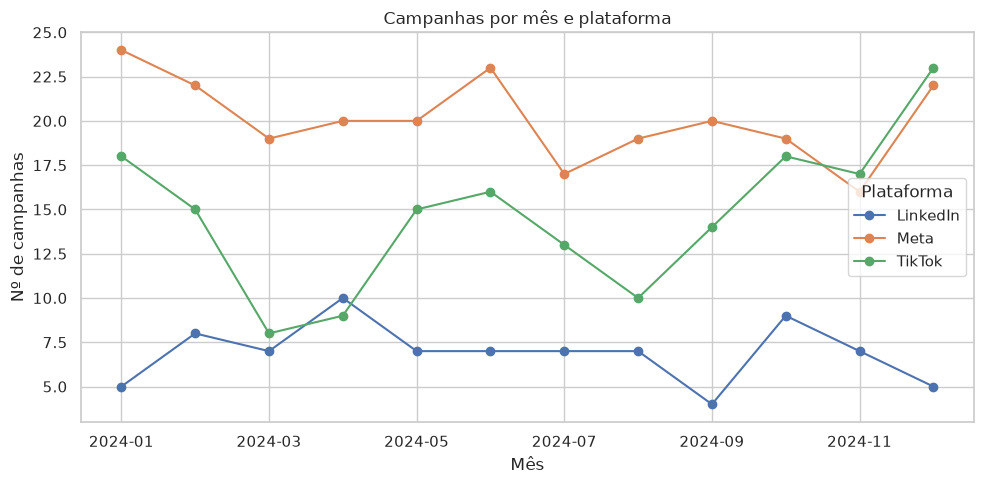

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
campanhas_mes_plataforma.plot(ax=ax, marker="o")
ax.set_title("Campanhas por mês e plataforma")
ax.set_xlabel("Mês")
ax.set_ylabel("Nº de campanhas")
ax.legend(title="Plataforma")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "campanhas_por_mes_e_plataforma.png", dpi=150)
plt.show()

## 7. Outliers

Para cada variável numérica: skewness, skewness após `log1p`, % de outliers pelo critério IQR (1.5×IQR) e um flag de distribuição log-normal. Critério de log-normal: skewness original > 1 **e** `|skewness(log1p(x))| < 0.5 * |skewness original|` (queda de pelo menos 50% na assimetria após o log).

In [11]:
NUMERIC_COLS = [
    "video_duration_s",
    "music_voice_ratio",
    "impressions",
    "clicks",
    "ctr",
    "cpc",
    "spend",
    "conversions",
    "revenue",
    "roas",
    "avg_watch_time_s",
    "engagement_rate",
    "klike_score",
]

outliers = eda.outlier_summary(df, NUMERIC_COLS)
outliers

,coluna,skewness,skewness_log1p,pct_outliers_iqr,parece_lognormal
0,video_duration_s,2.547,0.262,3.69,True
1,music_voice_ratio,0.245,-0.021,0.00,False
2,impressions,10.966,0.727,9.00,True
3,clicks,5.153,-0.210,9.80,True
4,ctr,0.434,0.385,0.00,False
5,cpc,9.894,2.745,13.98,True
6,spend,5.926,0.042,12.20,True
7,conversions,6.016,-0.004,12.20,True
8,revenue,8.317,-0.975,13.68,True
9,roas,4.390,0.576,5.40,True


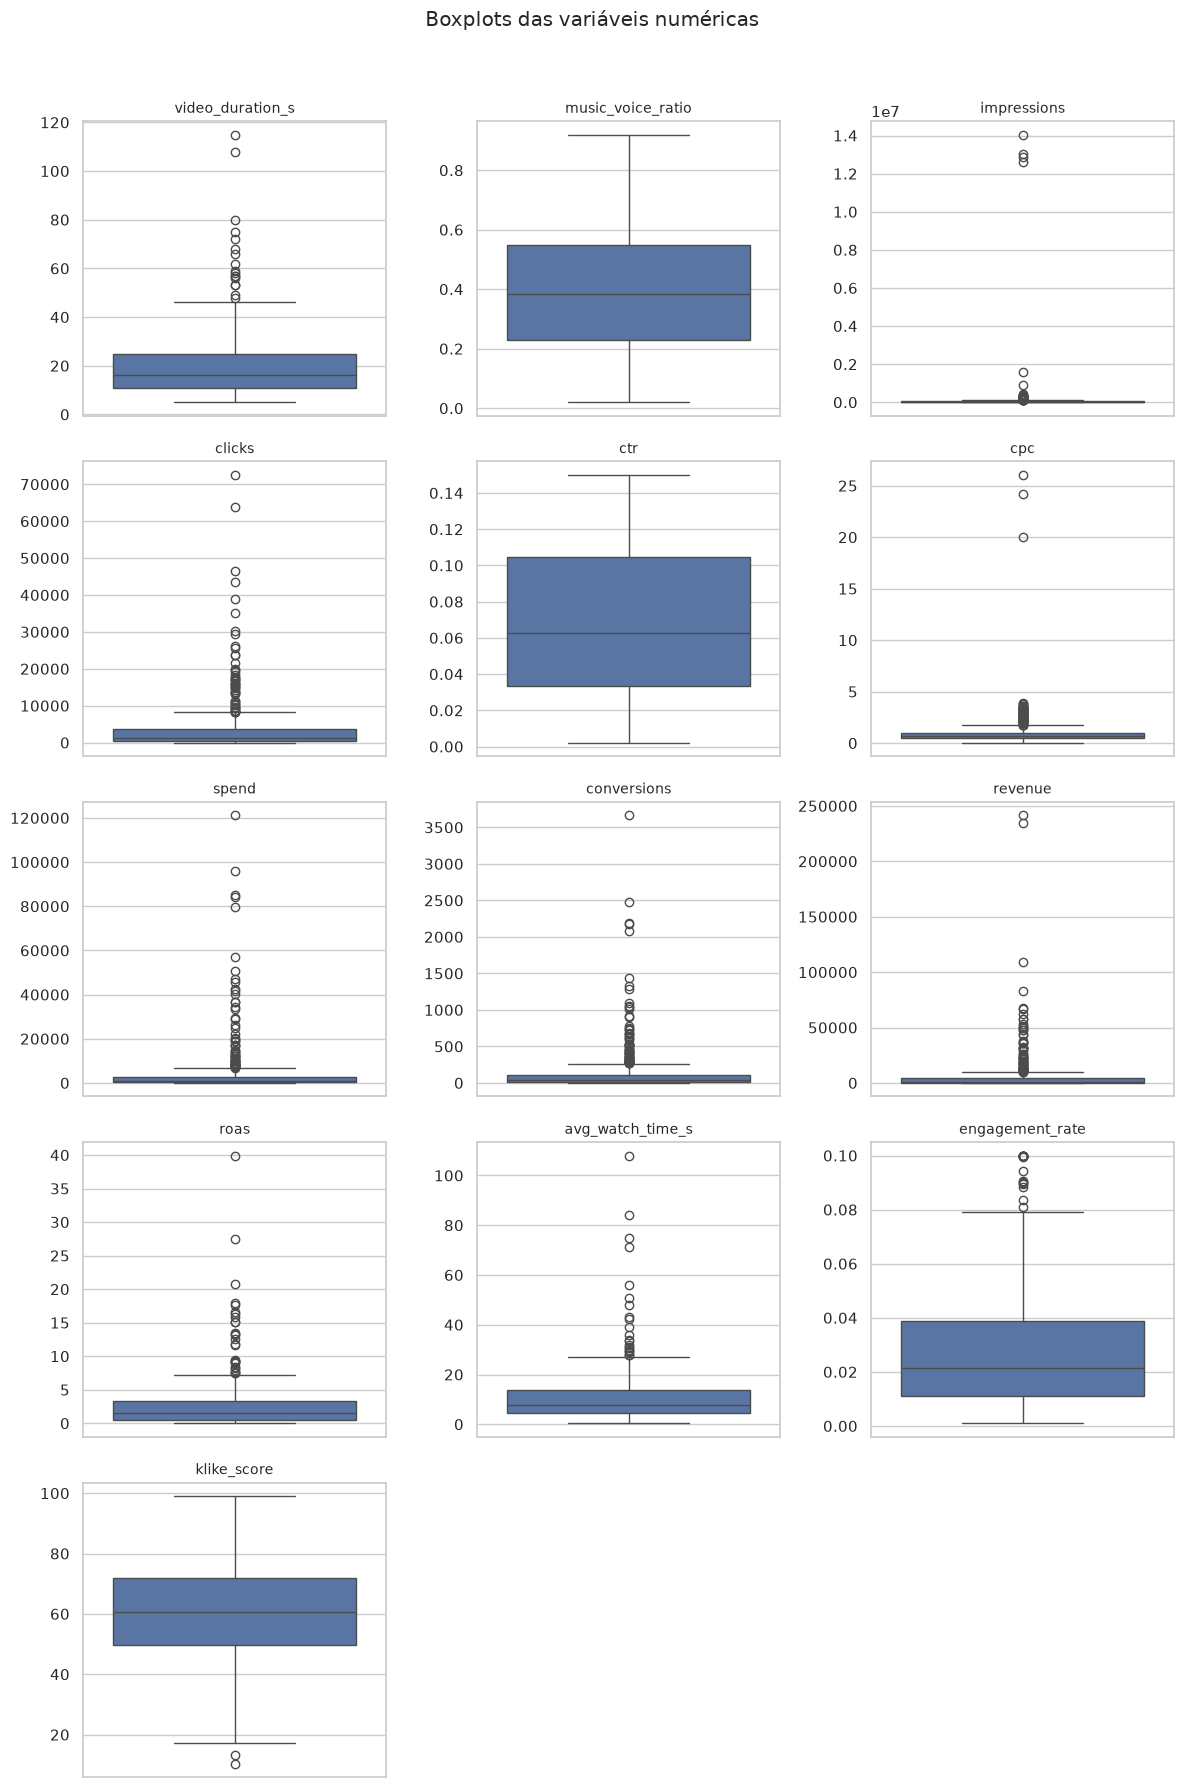

In [12]:
n_cols = 3
n_rows = -(-len(NUMERIC_COLS) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows))

for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.boxplot(y=df[col].dropna(), ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")

for ax in axes.flat[len(NUMERIC_COLS):]:
    ax.axis("off")

fig.suptitle("Boxplots das variáveis numéricas", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "boxplots_variaveis_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Tamanho dos grupos

Crosstab `platform x category` e `platform x objective`, com destaque em vermelho para células com `n < 20` (estimativas pouco confiáveis para esses subgrupos).

In [13]:
eda.group_size_table(df, "platform", "category", min_n=20)

category,App Install,Branding,E-commerce,Lead Gen,SaaS
platform,,,,,
LinkedIn,17,9,28,13,16
Meta,38,30,79,45,49
TikTok,27,24,58,35,32


In [14]:
eda.group_size_table(df, "platform", "objective", min_n=20)

objective,app_install,awareness,conversions,engagement,traffic
platform,,,,,
LinkedIn,7,10,26,10,30
Meta,21,24,84,45,67
TikTok,18,26,55,24,53


## Resumo dos achados

- **Bug corrigido:** `load_raw()` usava `.astype(bool)` nas colunas booleanas; isso convertia silenciosamente os 46 nulos de `has_subtitle` em `True`. Corrigido para `.astype("boolean")` (dtype nullable), que preserva os nulos. Os nulos de `has_subtitle` parecem majoritariamente aleatórios (n=46), com um sinal fraco e pouco confiável de leve associação com `category`/`ctr`.
- **Nulos:** além de `has_subtitle` (46), há nulos em `video_duration_s` (39), `music_voice_ratio` (38), `cpc` (28), `revenue` (25), `avg_watch_time_s` (27) e `engagement_rate` (32). Nenhuma outra coluna tem nulo.
- **Duplicatas:** nenhuma linha duplicada e nenhum `campaign_id` duplicado.
- **Categóricas:** todos os valores de `platform`, `category`, `objective`, `target_audience_age`, `format` e `text_density` estão dentro do dicionário de dados esperado — sem grafias inconsistentes.
- **Faixas válidas:** nenhuma violação em nenhuma das 11 regras (score em [0,100], ratios em [0,1], não-negativos, `clicks<=impressions`, `conversions<=clicks`).
- **Métricas derivadas:** `ctr` recalculado diverge >1% (relativo) em 16/500 linhas (3.2%); `cpc` em 6/500 (1.2%); `roas` em 27/424 linhas comparáveis (6.37%, excluindo 76 linhas com `revenue`=0, onde o erro relativo é indefinido). Não há denominador zero (`impressions`, `clicks`, `spend`) neste dataset. `avg_watch_time_s` nunca excede `video_duration_s`.
- **Datas:** campanhas de 2024-01-01 a 2024-12-30, com volume relativamente estável mês a mês entre as três plataformas.
- **Outliers/distribuição:** `impressions`, `clicks`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s` e `video_duration_s` são fortemente assimétricos (skew > 2.5) e passam o critério de log-normalidade (log1p reduz a assimetria em mais de 50%). `engagement_rate` é assimétrico (skew 1.3) mas não "limpa" com log1p. `music_voice_ratio`, `ctr` e `klike_score` têm distribuição aproximadamente simétrica.
- **Tamanho dos grupos:** `LinkedIn` é a plataforma com menos campanhas (n=83) e fica com `n<20` em várias combinações de `category` (App Install=17, Branding=9, Lead Gen=13, SaaS=16) e `objective` (app_install=7, awareness=10, engagement=10); `TikTok×app_install` também tem n=18.

## Tabela de tratamentos propostos

Nenhum tratamento foi aplicado nesta etapa — apenas diagnóstico. Os tratamentos abaixo são propostas para a etapa de modelagem (Parte 2), a serem implementados dentro de um `Pipeline`/`ColumnTransformer` do sklearn.

| Problema | Linhas afetadas | Tratamento proposto | Justificativa |
| :--- | :--- | :--- | :--- |
| Bug: nulos de `has_subtitle` virando `True` via `.astype(bool)` | 46 | Corrigido em `load_raw()` para `.astype("boolean")`; na modelagem, imputar como categoria "desconhecido" ou pela moda, dentro do Pipeline | Nulos parecem majoritariamente aleatórios (MAR/MCAR); um valor booleano inferido errado silenciosamente é pior que um nulo explícito |
| Nulos em `video_duration_s`, `music_voice_ratio`, `cpc`, `revenue`, `avg_watch_time_s`, `engagement_rate` | 39, 38, 28, 25, 27, 32 | `SimpleImputer` (mediana) dentro de `ColumnTransformer`, nunca aplicado manualmente antes do split/CV | Regra (c) do CLAUDE.md — evitar vazamento de dados; mediana é robusta às distribuições assimétricas identificadas na seção 7 |
| Divergência entre métrica informada e recalculada (`ctr` 3.2%, `cpc` 1.2%, `roas` 6.37%) | 16 / 6 / 27 | Manter o valor informado como fonte de verdade (é o que provavelmente alimentou o `klike_score`); não remover linhas, apenas documentar a divergência | Em dataset de 500 linhas, descartar dados por pequenas divergências (prováveis arredondamentos) tem custo alto e benefício incerto |
| `revenue` informado = 0 torna erro relativo do `roas` indefinido | 76 | Excluir essas linhas apenas do cálculo do erro relativo (já feito); manter os dados originais para modelagem | Divisão por zero aqui é uma condição matemática esperada (sem receita), não um erro de dado |
| Ausência de denominador zero em `impressions`, `clicks`, `spend` | 0 (nenhuma linha neste dataset) | Nenhum tratamento necessário agora; manter guard de divisão por zero no código (feature engineering / recommender) | Não ocorre nos dados atuais, mas pode ocorrer em dados futuros reais |
| Variáveis fortemente assimétricas / log-normais (`impressions`, `clicks`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s`, `video_duration_s`) | ver seção 7 (skew 2.5–11) | Aplicar `log1p` na etapa de feature engineering para modelos lineares; modelos baseados em árvore podem usar as variáveis originais | `log1p` reduz a assimetria em mais de 50% nessas colunas, diminuindo a influência de outliers em modelos sensíveis a escala |
| Outliers pelo critério IQR (até ~14% das linhas em `cpc`, `spend`, `conversions`, `revenue`) | ver seção 7 (0%–14%) | Não remover linhas; usar `RobustScaler` dentro do Pipeline e/ou preferir modelos robustos a outliers (árvores) | Remover 10–14% das 500 linhas é um custo alto de informação; os valores parecem extremos legítimos (campanhas de maior gasto/alcance), não erros de digitação |
| `engagement_rate` assimétrico mas não "log-normal limpo" pelo critério usado | n=500 | Avaliar `sqrt`/Box-Cox como alternativa ao `log1p`, ou manter como está e usar modelo robusto a assimetria | `log1p` só reduz a assimetria de 1.303 para 1.249 (queda < 50%), não atende ao critério de log-normalidade |
| Subgrupos pequenos (`platform x category`, `platform x objective` envolvendo `LinkedIn`/`TikTok`) | LinkedIn×App Install=17, ×Branding=9, ×Lead Gen=13, ×SaaS=16, ×app_install=7, ×awareness=10, ×engagement=10; TikTok×app_install=18 | Sempre reportar o `n` do subgrupo ao gerar recomendações contextuais (regra (e) do CLAUDE.md); considerar agregar categorias quando `n` for muito pequeno | Estimativas de efeito com `n<20` têm alta variância e podem levar o Recommendations Engine (Parte 3) a sugerir mudanças erradas |